In [6]:
import sys
sys.path.append("..")

from mdp import make_simple_gridworld
from planning import value_iteration
from qlearning import q_learning, extract_policy, print_q_and_policy
import matplotlib.pyplot as plt
import numpy as np

In [7]:
mdp = make_simple_gridworld(gamma=0.9)

V, vi_policy = value_iteration(mdp)
print("=== Value Iteration Policy ===")
print("Policy:", vi_policy)

=== Value Iteration Policy ===
Policy: [ 1  1  1 -1]


In [8]:
Q, returns = q_learning(mdp, num_episodes=8000, alpha=0.1, epsilon=0.2)
ql_policy = extract_policy(Q, mdp)

print("\n=== Q-Learning Results ===")
print_q_and_policy(mdp, Q, ql_policy)


=== Q-Learning Results ===
State |    Q(Left)   |   Q(Right)  | Policy
------|--------------|-------------|--------
  0   |      0.7019  |     0.7910  | Right
  1   |      0.7019  |     0.8900  | Right
  2   |      0.7910  |     1.0000  | Right
  3   |       -      |      -      |  ---- 


In [11]:
print("\n=== Policy Agreement Test ===")
print("Value Iteration policy:", vi_policy)
print("Q-Learning policy:     ", ql_policy)

if np.array_equal(vi_policy, ql_policy):
    print("\n SUCCESS: Both Policies are same!")
else:
    print("\n Policies are different. Q-learning may require more episodes.")


=== Policy Agreement Test ===
Value Iteration policy: [ 1  1  1 -1]
Q-Learning policy:      [ 1  1  1 -1]

 SUCCESS: Both Policies are same!


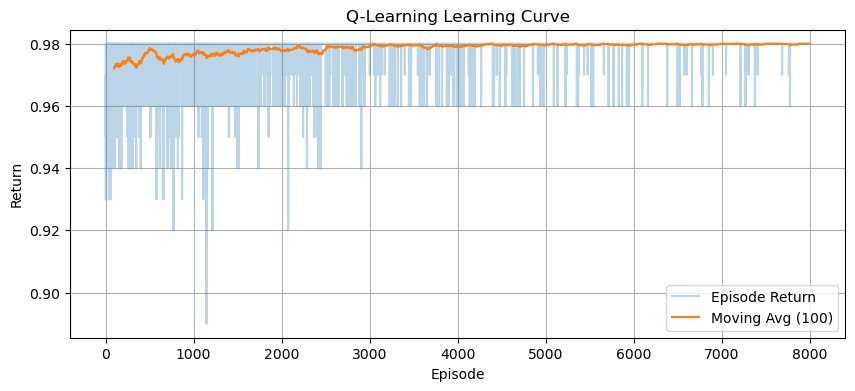

In [12]:
plt.figure(figsize=(10, 4))
plt.plot(returns, alpha=0.3, label="Episode Return")
# Moving average
window = 100
if len(returns) >= window:
    moving_avg = np.convolve(returns, np.ones(window)/window, mode='valid')
    plt.plot(range(window-1, len(returns)), moving_avg, label=f"Moving Avg ({window})")
plt.xlabel("Episode")
plt.ylabel("Return")
plt.title("Q-Learning Learning Curve")
plt.legend()
plt.grid(True)
plt.show()